# 03 — Image-Only EfficientNet-B0 Baseline

## Objective

This notebook establishes the image-only baseline for PAD-UFES-20 using a pretrained **EfficientNet-B0** model.

The baseline uses only clinical images and does not use patient or lesion metadata. Its purpose is to establish the performance achievable from visual information alone before evaluating multimodal approaches.

The experiment will:

- reuse the fixed patient-grouped cross-validation folds,
- apply consistent image preprocessing and augmentation,
- fine-tune a pretrained EfficientNet-B0 classifier,
- address class imbalance using training-fold class weights,
- evaluate predictions using macro-F1, balanced accuracy, AUROC, and per-class metrics,
- save fold-level predictions and metrics for later paired comparison with multimodal models.

All validation data remain untouched by training augmentation and class-balancing procedures.

## 1. Setup

Import the libraries required for image loading, model development, training, and evaluation, and configure reproducibility.

In [ ]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu128
Device: cuda


## 2. Load Fixed Fold Assignments and Image Paths

Load the audited dataset containing the fixed patient-grouped cross-validation folds and locate the extracted clinical images.

The same fold assignments created during the dataset audit are reused unchanged for this image-only baseline.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PAD_UFES_Capstone"
)

DATA_PATH = (
    PROJECT_ROOT
    / "metadata"
    / "pad_ufes_20_with_folds.csv"
)

IMAGE_DIR = Path("/content/pad_images")

df = pd.read_csv(DATA_PATH)

CLASS_NAMES = sorted(df["diagnostic"].unique())
CLASS_TO_IDX = {
    label: idx
    for idx, label in enumerate(CLASS_NAMES)
}

df["target"] = df["diagnostic"].map(CLASS_TO_IDX)

print("Dataset shape:", df.shape)
print("Number of classes:", len(CLASS_NAMES))
print("Classes:", CLASS_NAMES)
print("Image directory exists:", IMAGE_DIR.exists())

Mounted at /content/drive
Dataset shape: (2298, 29)
Number of classes: 6
Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
Image directory exists: False


## 3. Extract Clinical Images

The PAD-UFES-20 images are stored as ZIP archives in Google Drive.

Because the Colab runtime uses temporary local storage, the image archives are extracted into `/content/pad_images` at the start of the session. Local extraction provides faster image loading during model training than reading thousands of individual files directly from Google Drive.

In [ ]:
import zipfile

ZIP_DIR = PROJECT_ROOT / "data"
IMAGE_DIR = Path("/content/pad_images")

IMAGE_DIR.mkdir(parents=True, exist_ok=True)

zip_files = [
    ZIP_DIR / "imgs_part_1.zip",
    ZIP_DIR / "imgs_part_2.zip",
    ZIP_DIR / "imgs_part_3.zip",
]

for zip_path in zip_files:
    print(f"Extracting: {zip_path.name}")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(IMAGE_DIR)

print("\nExtraction complete.")

Extracting: imgs_part_1.zip
Extracting: imgs_part_2.zip
Extracting: imgs_part_3.zip

Extraction complete.


## 4. Verify Image Availability

Confirm that every image referenced in the metadata is available in the extracted image directory before constructing the PyTorch dataset.

In [ ]:
image_paths = {
    path.name: path
    for path in IMAGE_DIR.rglob("*")
    if path.is_file()
}

metadata_images = set(df["img_id"])
available_images = set(image_paths)

missing_images = metadata_images - available_images
extra_images = available_images - metadata_images

print("Metadata images:", len(metadata_images))
print("Extracted images:", len(available_images))
print("Missing images:", len(missing_images))
print("Extra images:", len(extra_images))

assert len(missing_images) == 0

print("\n✓ All metadata images are available.")

Metadata images: 2298
Extracted images: 2298
Missing images: 0
Extra images: 0

✓ All metadata images are available.


## 5. Define Image Transformations

Define separate preprocessing pipelines for training and validation images.

Training images use light geometric and colour augmentation to improve generalisation while preserving lesion appearance. Validation images use deterministic resizing and normalization only.

Both pipelines use ImageNet normalization to match the pretrained EfficientNet-B0 backbone.

In [ ]:
IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1,
        hue=0.02,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])

print("Training transform:")
print(train_transform)

print("\nValidation transform:")
print(val_transform)

Training transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=(-0.02, 0.02))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 6. Define Image Dataset

Create a PyTorch dataset that loads each clinical image using its `img_id` and returns the transformed image together with its numerical diagnostic target.

In [ ]:
class PADUFESImageDataset(Dataset):
    def __init__(self, dataframe, image_paths, transform=None):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.image_paths[row["img_id"]]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        target = int(row["target"])

        return image, target

## 7. Test Dataset Construction

Construct the training and validation datasets for Fold 0 and verify that images and targets are returned with the expected dimensions.

In [ ]:
VALIDATION_FOLD = 0

train_df = df[df["fold"] != VALIDATION_FOLD].copy()
val_df = df[df["fold"] == VALIDATION_FOLD].copy()

train_dataset = PADUFESImageDataset(
    train_df,
    image_paths,
    transform=train_transform,
)

val_dataset = PADUFESImageDataset(
    val_df,
    image_paths,
    transform=val_transform,
)

image, target = train_dataset[0]

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Image tensor shape:", image.shape)
print("Target:", target)
print("Target class:", CLASS_NAMES[target])

Training samples: 1838
Validation samples: 460
Image tensor shape: torch.Size([3, 224, 224])
Target: 1
Target class: BCC


## 8. Create DataLoaders

Create mini-batch data loaders for the training and validation datasets.

Training data are shuffled each epoch, while validation data remain in a fixed order. A moderate batch size is used to fit comfortably within the available Colab GPU memory.

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 58
Validation batches: 15


## 9. Validate DataLoader Output

Inspect one training batch to confirm that image and target tensors have the expected shapes and data types before model construction.

In [ ]:
images, targets = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Target batch shape:", targets.shape)

print("Image dtype:", images.dtype)
print("Target dtype:", targets.dtype)

print("Target range:", targets.min().item(), "to", targets.max().item())

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert targets.dtype == torch.int64
assert targets.min() >= 0
assert targets.max() < len(CLASS_NAMES)

print("\n✓ DataLoader output validated successfully.")

Image batch shape: torch.Size([32, 3, 224, 224])
Target batch shape: torch.Size([32])
Image dtype: torch.float32
Target dtype: torch.int64
Target range: 0 to 5

✓ DataLoader output validated successfully.


## 10. Define the EfficientNet-B0 Image-Only Model

Use an ImageNet-pretrained EfficientNet-B0 backbone and replace the original classification layer with a six-class output layer.

The full network will be fine-tuned so that the pretrained visual features can adapt to the clinical skin-lesion images.

In [ ]:
NUM_CLASSES = len(CLASS_NAMES)

weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1

model = models.efficientnet_b0(
    weights=weights
)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES,
)

model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 192MB/s]

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)


## 11. Verify Model Configuration

Confirm that the classifier produces six output logits and that the full EfficientNet-B0 network is trainable.

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

images, targets = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Output shape:", outputs.shape)

assert outputs.shape == (
    images.shape[0],
    NUM_CLASSES,
)

print("\n✓ EfficientNet-B0 configuration validated successfully.")

Total parameters: 4,015,234
Trainable parameters: 4,015,234
Output shape: torch.Size([32, 6])

✓ EfficientNet-B0 configuration validated successfully.


## 12. Compute Training-Fold Class Weights

Compute class weights using only the training partition of the current cross-validation fold.

Inverse-frequency weighting gives greater importance to underrepresented classes during optimization while leaving the validation distribution unchanged.

In [ ]:
class_counts = (
    train_df["target"]
    .value_counts()
    .sort_index()
)

num_training_samples = len(train_df)
num_classes = len(CLASS_NAMES)

class_weights = (
    num_training_samples
    / (num_classes * class_counts.values)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device,
)

class_weight_table = pd.DataFrame({
    "class": CLASS_NAMES,
    "count": class_counts.values,
    "weight": class_weights.cpu().numpy(),
})

display(class_weight_table)

,class,count,weight
0,ACK,586,0.522753
1,BCC,672,0.455853
2,MEL,39,7.854701
3,NEV,199,1.539364
4,SCC,155,1.976344
5,SEK,187,1.638146


## 13. Validate Class Weights

Confirm that all six classes are represented in the training fold and that rarer classes receive larger loss weights.

In [ ]:
assert len(class_counts) == NUM_CLASSES
assert torch.isfinite(class_weights).all()
assert (class_weights > 0).all()

print("Class weights:", class_weights)

print(
    "\nHighest weight:",
    CLASS_NAMES[class_weights.argmax().item()]
)

print(
    "Lowest weight:",
    CLASS_NAMES[class_weights.argmin().item()]
)

print("\n✓ Class weights validated successfully.")

Class weights: tensor([0.5228, 0.4559, 7.8547, 1.5394, 1.9763, 1.6381], device='cuda:0')

Highest weight: MEL
Lowest weight: BCC

✓ Class weights validated successfully.


## 14. Define Loss Function and Optimizer

Use class-weighted cross-entropy loss so that errors on underrepresented diagnostic classes contribute more strongly during training.

The full pretrained EfficientNet-B0 network is fine-tuned using AdamW with a small learning rate to preserve useful pretrained visual representations while adapting them to PAD-UFES-20.

In [ ]:
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

Loss: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001


## 15. Define Learning-Rate Scheduler

Reduce the learning rate when validation macro-F1 stops improving.

Macro-F1 is used because it gives equal importance to each diagnostic class and is therefore more informative than overall accuracy for the imbalanced PAD-UFES-20 dataset.

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

print("Scheduler:", scheduler.__class__.__name__)

Scheduler: ReduceLROnPlateau


## 16. Define Validation Function

Define a reusable evaluation function that calculates validation loss, macro-F1, balanced accuracy, predictions, and class probabilities.

The model is evaluated without gradient updates or training-time augmentation.

In [ ]:
def evaluate_model(
    model,
    data_loader,
    criterion,
    device,
):
    model.eval()

    running_loss = 0.0

    all_targets = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, targets in data_loader:

            images = images.to(
                device,
                non_blocking=True,
            )

            targets = targets.to(
                device,
                non_blocking=True,
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                targets,
            )

            probabilities = torch.softmax(
                outputs,
                dim=1,
            )

            predictions = outputs.argmax(
                dim=1
            )

            running_loss += (
                loss.item()
                * images.size(0)
            )

            all_targets.extend(
                targets.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

    all_targets = np.asarray(
        all_targets
    )

    all_predictions = np.asarray(
        all_predictions
    )

    all_probabilities = np.concatenate(
        all_probabilities,
        axis=0,
    )

    validation_loss = (
        running_loss
        / len(data_loader.dataset)
    )

    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro",
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            all_targets,
            all_predictions,
        )
    )

    return {
        "loss": validation_loss,
        "macro_f1": macro_f1,
        "balanced_accuracy": balanced_accuracy,
        "targets": all_targets,
        "predictions": all_predictions,
        "probabilities": all_probabilities,
    }

## 17. Test Validation Function

Run one evaluation pass before training to verify that the validation function executes correctly and returns predictions for every validation sample.

In [ ]:
initial_metrics = evaluate_model(
    model,
    val_loader,
    criterion,
    device,
)

print(
    f"Initial validation loss: "
    f"{initial_metrics['loss']:.4f}"
)

print(
    f"Initial macro-F1: "
    f"{initial_metrics['macro_f1']:.4f}"
)

print(
    f"Initial balanced accuracy: "
    f"{initial_metrics['balanced_accuracy']:.4f}"
)

print(
    "Probability shape:",
    initial_metrics["probabilities"].shape,
)

assert (
    initial_metrics["probabilities"].shape
    == (len(val_dataset), NUM_CLASSES)
)

print(
    "\n✓ Validation function executed successfully."
)

Initial validation loss: 1.7915
Initial macro-F1: 0.1718
Initial balanced accuracy: 0.1918
Probability shape: (460, 6)

✓ Validation function executed successfully.


## 18. Define Training Function

Train the model for one epoch using class-weighted cross-entropy loss.

The function returns the average training loss for the epoch.

In [ ]:
def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    device,
):
    model.train()

    running_loss = 0.0

    for images, targets in data_loader:

        images = images.to(
            device,
            non_blocking=True,
        )

        targets = targets.to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            targets,
        )

        loss.backward()
        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

    epoch_loss = (
        running_loss
        / len(data_loader.dataset)
    )

    return epoch_loss

## 19. Configure Training and Early Stopping

Train for a maximum number of epochs while monitoring validation macro-F1.

The model state with the highest validation macro-F1 is retained. Training stops early if validation macro-F1 does not improve for several consecutive epochs.

In [ ]:
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "checkpoints"
    / "image_only"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"efficientnet_b0_fold_{VALIDATION_FOLD}.pt"
)

print("Checkpoint path:")
print(CHECKPOINT_PATH)

Checkpoint path:
/content/drive/MyDrive/PAD_UFES_Capstone/checkpoints/image_only/efficientnet_b0_fold_0.pt


## 20. Train Fold 0

Fine-tune EfficientNet-B0 on the Fold 0 training partition.

Validation macro-F1 is used for model selection and learning-rate scheduling. The best-performing model checkpoint is saved for later evaluation.

In [ ]:
history = []

best_macro_f1 = -np.inf
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device,
    )

    val_metrics = evaluate_model(
        model,
        val_loader,
        criterion,
        device,
    )

    val_loss = val_metrics["loss"]
    val_macro_f1 = val_metrics["macro_f1"]
    val_balanced_accuracy = val_metrics[
        "balanced_accuracy"
    ]

    scheduler.step(
        val_macro_f1
    )

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - start_time

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_macro_f1,
        "val_balanced_accuracy": val_balanced_accuracy,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Balanced Acc: {val_balanced_accuracy:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1

        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH,
        )

        print("  ✓ New best model saved.")

    else:

        epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):
            print(
                "\nEarly stopping triggered."
            )
            break

Epoch 01 | Train Loss: 1.6792 | Val Loss: 1.4925 | Macro-F1: 0.4358 | Balanced Acc: 0.5036 | LR: 1.00e-04 | Time: 98.6s
  ✓ New best model saved.
Epoch 02 | Train Loss: 1.2865 | Val Loss: 1.1336 | Macro-F1: 0.5899 | Balanced Acc: 0.6213 | LR: 1.00e-04 | Time: 95.2s
  ✓ New best model saved.
Epoch 03 | Train Loss: 1.0154 | Val Loss: 0.9290 | Macro-F1: 0.6136 | Balanced Acc: 0.6628 | LR: 1.00e-04 | Time: 94.3s
  ✓ New best model saved.
Epoch 04 | Train Loss: 0.8208 | Val Loss: 0.8485 | Macro-F1: 0.6436 | Balanced Acc: 0.6699 | LR: 1.00e-04 | Time: 93.4s
  ✓ New best model saved.
Epoch 05 | Train Loss: 0.6695 | Val Loss: 0.8052 | Macro-F1: 0.6683 | Balanced Acc: 0.6840 | LR: 1.00e-04 | Time: 94.5s
  ✓ New best model saved.
Epoch 06 | Train Loss: 0.6236 | Val Loss: 0.8560 | Macro-F1: 0.6338 | Balanced Acc: 0.6378 | LR: 1.00e-04 | Time: 93.3s
Epoch 07 | Train Loss: 0.5439 | Val Loss: 0.7976 | Macro-F1: 0.6386 | Balanced Acc: 0.6588 | LR: 1.00e-04 | Time: 92.9s
Epoch 08 | Train Loss: 0.4411 

## 21. Restore the Best Fold 0 Model

Early stopping terminated training after the validation macro-F1 failed to improve for five consecutive epochs.

The checkpoint corresponding to the highest validation macro-F1 is reloaded before final Fold 0 evaluation so that the reported results represent the best-performing model obtained during training.

In [ ]:
model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=True,
    )
)

model.eval()

print("✓ Best Fold 0 checkpoint restored.")
print("Best validation macro-F1 during training:", round(best_macro_f1, 4))

✓ Best Fold 0 checkpoint restored.
Best validation macro-F1 during training: 0.6683


## 22. Final Fold 0 Evaluation

Evaluate the restored best checkpoint on the Fold 0 held-out partition and retain the predictions and class probabilities for subsequent class-level analysis.

In [ ]:
fold0_metrics = evaluate_model(
    model,
    val_loader,
    criterion,
    device,
)

print(f"Validation loss:       {fold0_metrics['loss']:.4f}")
print(f"Macro-F1:              {fold0_metrics['macro_f1']:.4f}")
print(f"Balanced accuracy:     {fold0_metrics['balanced_accuracy']:.4f}")

print("\nPredictions:", fold0_metrics["predictions"].shape)
print("Probabilities:", fold0_metrics["probabilities"].shape)

assert (
    len(fold0_metrics["targets"])
    == len(val_df)
)

print("\n✓ Final Fold 0 evaluation completed.")

Validation loss:       0.8052
Macro-F1:              0.6683
Balanced accuracy:     0.6840

Predictions: (460,)
Probabilities: (460, 6)

✓ Final Fold 0 evaluation completed.


## 23. Class-Level Performance

Evaluate precision, recall, and F1-score for each diagnostic class.

Class-level analysis is important because PAD-UFES-20 is strongly imbalanced, and aggregate metrics alone may hide poor performance on minority classes such as melanoma.

In [ ]:
from sklearn.metrics import classification_report

report_dict = classification_report(
    fold0_metrics["targets"],
    fold0_metrics["predictions"],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

class_report = pd.DataFrame(
    report_dict
).T

display(
    class_report.loc[
        CLASS_NAMES,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

,precision,recall,f1-score,support
ACK,0.7787,0.6597,0.7143,144.0
BCC,0.7697,0.6763,0.7200,173.0
MEL,0.8333,0.7692,0.8000,13.0
NEV,0.7708,0.8222,0.7957,45.0
SCC,0.2239,0.4054,0.2885,37.0
SEK,0.6271,0.7708,0.6916,48.0


## 24. Confusion Matrix

Visualise the Fold 0 confusion matrix to examine which diagnostic classes are most frequently confused.

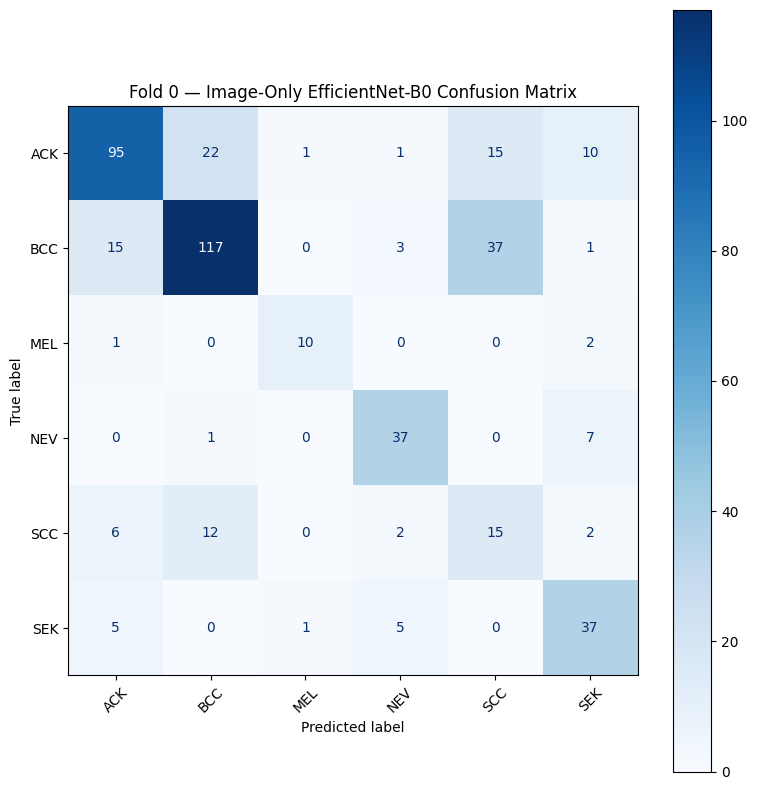

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ConfusionMatrixDisplay.from_predictions(
    fold0_metrics["targets"],
    fold0_metrics["predictions"],
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
)

ax.set_title(
    "Fold 0 — Image-Only EfficientNet-B0 Confusion Matrix"
)

plt.tight_layout()
plt.show()

## 25. Multiclass AUROC

Compute one-vs-rest multiclass AUROC using the predicted class probabilities.

AUROC provides an additional probability-based measure of discrimination and complements macro F1-score and balanced accuracy.

In [ ]:
from sklearn.metrics import roc_auc_score

macro_auroc = roc_auc_score(
    fold0_metrics["targets"],
    fold0_metrics["probabilities"],
    multi_class="ovr",
    average="macro",
)

weighted_auroc = roc_auc_score(
    fold0_metrics["targets"],
    fold0_metrics["probabilities"],
    multi_class="ovr",
    average="weighted",
)

print(f"Macro AUROC:    {macro_auroc:.4f}")
print(f"Weighted AUROC: {weighted_auroc:.4f}")

Macro AUROC:    0.9130
Weighted AUROC: 0.9107


## 26. Create an Inner Validation Split

The initial Fold 0 experiment used the outer held-out partition for early stopping and model selection. To obtain a cleaner estimate of generalisation, the final cross-validation protocol separates model selection from final evaluation.

For each outer fold:

- the outer training partition is divided into inner-training and inner-validation subsets,
- patient grouping is preserved to prevent patient leakage,
- the inner-validation subset is used for early stopping and learning-rate scheduling,
- the outer held-out fold remains untouched until final evaluation.

This nested training structure will be applied consistently across the final experiments.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

OUTER_FOLD = 0
INNER_SEED = 42

# Outer split
outer_train_df = df[
    df["fold"] != OUTER_FOLD
].copy()

outer_val_df = df[
    df["fold"] == OUTER_FOLD
].copy()

# Create approximately 80/20 split within outer training data
inner_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=INNER_SEED,
)

inner_train_idx, inner_val_idx = next(
    inner_splitter.split(
        outer_train_df,
        y=outer_train_df["diagnostic"],
        groups=outer_train_df["patient_id"],
    )
)

inner_train_df = outer_train_df.iloc[
    inner_train_idx
].copy()

inner_val_df = outer_train_df.iloc[
    inner_val_idx
].copy()

print("Outer fold:", OUTER_FOLD)

print("\nInner training samples:", len(inner_train_df))
print("Inner validation samples:", len(inner_val_df))
print("Outer held-out samples:", len(outer_val_df))

Outer fold: 0

Inner training samples: 1489
Inner validation samples: 349
Outer held-out samples: 460


## 27. Validate Patient Separation

Verify that no patient is shared between the inner-training, inner-validation, and outer held-out partitions.

In [ ]:
inner_train_patients = set(
    inner_train_df["patient_id"]
)

inner_val_patients = set(
    inner_val_df["patient_id"]
)

outer_val_patients = set(
    outer_val_df["patient_id"]
)

assert inner_train_patients.isdisjoint(
    inner_val_patients
)

assert inner_train_patients.isdisjoint(
    outer_val_patients
)

assert inner_val_patients.isdisjoint(
    outer_val_patients
)

print(
    "Inner training patients:",
    len(inner_train_patients)
)

print(
    "Inner validation patients:",
    len(inner_val_patients)
)

print(
    "Outer held-out patients:",
    len(outer_val_patients)
)

print(
    "\n✓ No patient overlap between partitions."
)

Inner training patients: 881
Inner validation patients: 219
Outer held-out patients: 273

✓ No patient overlap between partitions.


## 28. Check Class Distribution Across Nested Partitions

Inspect the diagnostic class distribution in the inner-training, inner-validation, and outer held-out partitions.

This check ensures that all six diagnostic classes are represented after patient-grouped splitting, with particular attention to melanoma because it is the smallest class in PAD-UFES-20.

In [ ]:
def class_distribution(dataframe, name):
    counts = (
        dataframe["diagnostic"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )

    percentages = (
        counts / len(dataframe) * 100
    )

    return pd.DataFrame({
        f"{name}_count": counts,
        f"{name}_percent": percentages.round(2),
    })


distribution_table = pd.concat(
    [
        class_distribution(
            inner_train_df,
            "inner_train"
        ),
        class_distribution(
            inner_val_df,
            "inner_val"
        ),
        class_distribution(
            outer_val_df,
            "outer_heldout"
        ),
    ],
    axis=1,
)

display(distribution_table)

# Verify every partition contains every class
assert (
    distribution_table[
        [
            "inner_train_count",
            "inner_val_count",
            "outer_heldout_count",
        ]
    ] > 0
).all().all()

print(
    "\n✓ All six classes are represented "
    "in every partition."
)

,inner_train_count,inner_train_percent,inner_val_count,inner_val_percent,outer_heldout_count,outer_heldout_percent
diagnostic,,,,,,
ACK,483,32.44,103,29.51,144,31.30
BCC,530,35.59,142,40.69,173,37.61
MEL,34,2.28,5,1.43,13,2.83
NEV,165,11.08,34,9.74,45,9.78
SCC,129,8.66,26,7.45,37,8.04
SEK,148,9.94,39,11.17,48,10.43



✓ All six classes are represented in every partition.


## 29. Compute Inner-Training Class Weights

Class weights are recalculated using only the inner-training partition.

This ensures that information from the inner-validation and outer held-out partitions is not used when configuring the training loss.

In [ ]:
inner_class_counts = (
    inner_train_df["target"]
    .value_counts()
    .sort_index()
)

inner_class_weights = (
    len(inner_train_df)
    / (NUM_CLASSES * inner_class_counts.values)
)

inner_class_weights = torch.tensor(
    inner_class_weights,
    dtype=torch.float32,
    device=device,
)

inner_weight_table = pd.DataFrame({
    "class": CLASS_NAMES,
    "count": inner_class_counts.values,
    "weight": inner_class_weights.cpu().numpy(),
})

display(inner_weight_table)

assert len(inner_class_counts) == NUM_CLASSES
assert torch.isfinite(inner_class_weights).all()
assert (inner_class_weights > 0).all()

print("\n✓ Inner-training class weights validated.")

,class,count,weight
0,ACK,483,0.513803
1,BCC,530,0.468239
2,MEL,34,7.299020
3,NEV,165,1.504040
4,SCC,129,1.923773
5,SEK,148,1.676802



✓ Inner-training class weights validated.


## 30. Create Nested Training DataLoaders

Create separate datasets and data loaders for:

- inner training,
- inner validation,
- outer held-out evaluation.

Training augmentation is applied only to the inner-training partition. Validation and held-out images use deterministic preprocessing.

In [ ]:
inner_train_dataset = PADUFESImageDataset(
    inner_train_df,
    image_paths,
    transform=train_transform,
)

inner_val_dataset = PADUFESImageDataset(
    inner_val_df,
    image_paths,
    transform=val_transform,
)

outer_val_dataset = PADUFESImageDataset(
    outer_val_df,
    image_paths,
    transform=val_transform,
)


inner_train_loader = DataLoader(
    inner_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

inner_val_loader = DataLoader(
    inner_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

outer_val_loader = DataLoader(
    outer_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)


print("Inner train batches:", len(inner_train_loader))
print("Inner validation batches:", len(inner_val_loader))
print("Outer held-out batches:", len(outer_val_loader))

Inner train batches: 47
Inner validation batches: 11
Outer held-out batches: 15


## 31. Validate Nested DataLoaders

Check the shape and label range of batches from each partition before retraining the model.

In [ ]:
for loader_name, loader in [
    ("Inner train", inner_train_loader),
    ("Inner validation", inner_val_loader),
    ("Outer held-out", outer_val_loader),
]:

    images, targets = next(iter(loader))

    print(
        f"{loader_name}: "
        f"images={images.shape}, "
        f"targets={targets.shape}, "
        f"label range={targets.min().item()}-{targets.max().item()}"
    )

    assert images.ndim == 4
    assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
    assert targets.min() >= 0
    assert targets.max() < NUM_CLASSES

print("\n✓ Nested DataLoaders validated successfully.")

Inner train: images=torch.Size([32, 3, 224, 224]), targets=torch.Size([32]), label range=0-5
Inner validation: images=torch.Size([32, 3, 224, 224]), targets=torch.Size([32]), label range=0-5
Outer held-out: images=torch.Size([32, 3, 224, 224]), targets=torch.Size([32]), label range=0-5

✓ Nested DataLoaders validated successfully.


## 32. Reinitialize EfficientNet-B0 for Nested Fold 0

A fresh pretrained EfficientNet-B0 model is created for the final nested Fold 0 experiment.

The previous model was used only for the pilot experiment and is not reused here.

In [ ]:
# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Fresh pretrained model
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1

nested_model = models.efficientnet_b0(
    weights=weights
)

in_features = nested_model.classifier[1].in_features

nested_model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES,
)

nested_model = nested_model.to(device)

print("✓ Fresh EfficientNet-B0 initialized.")
print(nested_model.classifier)

✓ Fresh EfficientNet-B0 initialized.
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)


## 33. Configure Nested Training

The nested model uses class weights calculated only from the inner-training partition.

AdamW is used for optimization, while validation macro-F1 from the inner-validation partition controls learning-rate scheduling and early stopping.

In [ ]:
nested_criterion = nn.CrossEntropyLoss(
    weight=inner_class_weights
)

nested_optimizer = torch.optim.AdamW(
    nested_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

nested_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    nested_optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

print("Loss:", nested_criterion)
print("Optimizer:", nested_optimizer.__class__.__name__)
print("Scheduler:", nested_scheduler.__class__.__name__)

Loss: CrossEntropyLoss()
Optimizer: AdamW
Scheduler: ReduceLROnPlateau


## 34. Train Nested Fold 0

Train the model using the inner-training partition and monitor macro-F1 on the inner-validation partition.

The outer held-out Fold 0 partition is not used during training, learning-rate scheduling, checkpoint selection, or early stopping.

In [ ]:
NESTED_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / "efficientnet_b0_fold_0_nested.pt"
)

nested_history = []

best_inner_macro_f1 = -np.inf
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    train_loss = train_one_epoch(
        nested_model,
        inner_train_loader,
        nested_criterion,
        nested_optimizer,
        device,
    )

    inner_val_metrics = evaluate_model(
        nested_model,
        inner_val_loader,
        nested_criterion,
        device,
    )

    inner_val_loss = inner_val_metrics["loss"]
    inner_macro_f1 = inner_val_metrics["macro_f1"]
    inner_balanced_accuracy = inner_val_metrics[
        "balanced_accuracy"
    ]

    nested_scheduler.step(
        inner_macro_f1
    )

    current_lr = nested_optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - start_time

    nested_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "inner_val_loss": inner_val_loss,
        "inner_macro_f1": inner_macro_f1,
        "inner_balanced_accuracy": inner_balanced_accuracy,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Inner Val Loss: {inner_val_loss:.4f} | "
        f"Macro-F1: {inner_macro_f1:.4f} | "
        f"Balanced Acc: {inner_balanced_accuracy:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

    if inner_macro_f1 > best_inner_macro_f1:

        best_inner_macro_f1 = inner_macro_f1
        epochs_without_improvement = 0

        torch.save(
            nested_model.state_dict(),
            NESTED_CHECKPOINT_PATH,
        )

        print("  ✓ New best nested model saved.")

    else:

        epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):
            print(
                "\nEarly stopping triggered."
            )
            break

Epoch 01 | Train Loss: 1.7027 | Inner Val Loss: 1.5676 | Macro-F1: 0.3924 | Balanced Acc: 0.4599 | LR: 1.00e-04 | Time: 77.2s
  ✓ New best nested model saved.
Epoch 02 | Train Loss: 1.3874 | Inner Val Loss: 1.2760 | Macro-F1: 0.4781 | Balanced Acc: 0.5596 | LR: 1.00e-04 | Time: 74.9s
  ✓ New best nested model saved.
Epoch 03 | Train Loss: 1.0903 | Inner Val Loss: 1.0882 | Macro-F1: 0.5186 | Balanced Acc: 0.5994 | LR: 1.00e-04 | Time: 76.3s
  ✓ New best nested model saved.
Epoch 04 | Train Loss: 0.8909 | Inner Val Loss: 1.0047 | Macro-F1: 0.5343 | Balanced Acc: 0.6241 | LR: 1.00e-04 | Time: 74.9s
  ✓ New best nested model saved.
Epoch 05 | Train Loss: 0.7335 | Inner Val Loss: 0.9868 | Macro-F1: 0.5720 | Balanced Acc: 0.6401 | LR: 1.00e-04 | Time: 74.8s
  ✓ New best nested model saved.
Epoch 06 | Train Loss: 0.6371 | Inner Val Loss: 0.9991 | Macro-F1: 0.5837 | Balanced Acc: 0.6440 | LR: 1.00e-04 | Time: 75.4s
  ✓ New best nested model saved.
Epoch 07 | Train Loss: 0.5342 | Inner Val Loss

## 35. Select the Training Duration

The inner-validation experiment identified epoch 6 as the best training point based on validation macro-F1.

This selected epoch count is now treated as a training hyperparameter for Outer Fold 0. A fresh model will be trained using the complete outer-training partition for exactly six epochs before being evaluated once on the untouched outer held-out partition.

In [ ]:
nested_history_df = pd.DataFrame(nested_history)

best_row = nested_history_df.loc[
    nested_history_df["inner_macro_f1"].idxmax()
]

SELECTED_EPOCHS = int(best_row["epoch"])

print("Selected epoch:", SELECTED_EPOCHS)
print(
    "Best inner macro-F1:",
    f"{best_row['inner_macro_f1']:.4f}"
)
print(
    "Inner balanced accuracy:",
    f"{best_row['inner_balanced_accuracy']:.4f}"
)

assert SELECTED_EPOCHS == 6

Selected epoch: 6
Best inner macro-F1: 0.5837
Inner balanced accuracy: 0.6440


## 36. Prepare Full Outer-Training Partition

After selecting the training duration using the inner split, the complete outer-training partition is restored.

All 1,838 available training samples are used for the final Fold 0 model. The 460 outer held-out samples remain untouched.

In [ ]:
outer_train_dataset = PADUFESImageDataset(
    outer_train_df,
    image_paths,
    transform=train_transform,
)

outer_train_loader = DataLoader(
    outer_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

print(
    "Full outer-training samples:",
    len(outer_train_dataset)
)

print(
    "Outer held-out samples:",
    len(outer_val_dataset)
)

print(
    "Training batches:",
    len(outer_train_loader)
)

print(
    "Held-out batches:",
    len(outer_val_loader)
)

Full outer-training samples: 1838
Outer held-out samples: 460
Training batches: 58
Held-out batches: 15


In [ ]:
outer_class_counts = (
    outer_train_df["target"]
    .value_counts()
    .sort_index()
)

outer_class_weights = (
    len(outer_train_df)
    / (NUM_CLASSES * outer_class_counts.values)
)

outer_class_weights = torch.tensor(
    outer_class_weights,
    dtype=torch.float32,
    device=device,
)

outer_weight_table = pd.DataFrame({
    "class": CLASS_NAMES,
    "count": outer_class_counts.values,
    "weight": outer_class_weights.cpu().numpy(),
})

display(outer_weight_table)

,class,count,weight
0,ACK,586,0.522753
1,BCC,672,0.455853
2,MEL,39,7.854701
3,NEV,199,1.539364
4,SCC,155,1.976344
5,SEK,187,1.638146


## 37. Train the Final Outer Fold 0 Model

The inner-validation experiment selected six training epochs for Outer Fold 0.

A fresh EfficientNet-B0 model is now trained on the complete outer-training partition for exactly six epochs. The outer held-out partition is not evaluated or otherwise accessed during this training stage.

Class weights are recalculated using the complete outer-training partition.

In [ ]:
# Reset random state before final training
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# Fresh model
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1

final_model = models.efficientnet_b0(
    weights=weights
)

in_features = final_model.classifier[1].in_features

final_model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES,
)

final_model = final_model.to(device)


# Loss and optimizer
final_criterion = nn.CrossEntropyLoss(
    weight=outer_class_weights
)

final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("✓ Fresh final Fold 0 model initialized.")
print("Training epochs:", SELECTED_EPOCHS)
print("Training samples:", len(outer_train_dataset))

✓ Fresh final Fold 0 model initialized.
Training epochs: 6
Training samples: 1838


## 38. Final Fold 0 Training

Train the final model for the six epochs selected by the inner-validation experiment.

No validation-based model selection is performed during this stage.

In [ ]:
final_history = []

for epoch in range(1, SELECTED_EPOCHS + 1):

    start_time = time.time()

    train_loss = train_one_epoch(
        final_model,
        outer_train_loader,
        final_criterion,
        final_optimizer,
        device,
    )

    epoch_time = time.time() - start_time

    final_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "learning_rate": final_optimizer.param_groups[0]["lr"],
        "epoch_time_seconds": epoch_time,
    })

    print(
        f"Epoch {epoch:02d}/{SELECTED_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"LR: {final_optimizer.param_groups[0]['lr']:.2e} | "
        f"Time: {epoch_time:.1f}s"
    )

Epoch 01/6 | Train Loss: 1.6790 | LR: 1.00e-04 | Time: 80.9s
Epoch 02/6 | Train Loss: 1.3041 | LR: 1.00e-04 | Time: 76.5s
Epoch 03/6 | Train Loss: 0.9961 | LR: 1.00e-04 | Time: 78.5s
Epoch 04/6 | Train Loss: 0.8295 | LR: 1.00e-04 | Time: 76.2s
Epoch 05/6 | Train Loss: 0.6969 | LR: 1.00e-04 | Time: 76.7s
Epoch 06/6 | Train Loss: 0.5564 | LR: 1.00e-04 | Time: 77.0s


In [ ]:
FINAL_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / "efficientnet_b0_fold_0_final.pt"
)

torch.save(
    final_model.state_dict(),
    FINAL_CHECKPOINT_PATH,
)

print(
    "✓ Final Fold 0 model saved to:",
    FINAL_CHECKPOINT_PATH
)

✓ Final Fold 0 model saved to: /content/drive/MyDrive/PAD_UFES_Capstone/checkpoints/image_only/efficientnet_b0_fold_0_final.pt


## 39. Evaluate the Final Outer Fold 0 Model

The final model is evaluated once on the untouched outer held-out partition.

This partition was not used for early stopping, learning-rate scheduling, checkpoint selection, or training-duration selection. Its performance therefore represents the final Fold 0 estimate for the image-only EfficientNet-B0 baseline.

In [ ]:
outer_metrics = evaluate_model(
    final_model,
    outer_val_loader,
    final_criterion,
    device,
)

print(
    "Outer held-out loss:",
    f"{outer_metrics['loss']:.4f}"
)

print(
    "Outer macro-F1:",
    f"{outer_metrics['macro_f1']:.4f}"
)

print(
    "Outer balanced accuracy:",
    f"{outer_metrics['balanced_accuracy']:.4f}"
)

print(
    "Prediction shape:",
    outer_metrics["predictions"].shape
)

print(
    "Probability shape:",
    outer_metrics["probabilities"].shape
)

Outer held-out loss: 1.0257
Outer macro-F1: 0.6182
Outer balanced accuracy: 0.6352
Prediction shape: (460,)
Probability shape: (460, 6)


## 40. Per-Class Performance

Because PAD-UFES-20 is strongly class-imbalanced, overall metrics are supplemented with precision, recall, and F1-score for each diagnostic class.

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    outer_metrics["targets"],
    outer_metrics["predictions"],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T

display(
    report_df.loc[
        CLASS_NAMES,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

,precision,recall,f1-score,support
ACK,0.7674,0.6875,0.7253,144.0
BCC,0.7803,0.5954,0.6754,173.0
MEL,0.6667,0.6154,0.6400,13.0
NEV,0.7561,0.6889,0.7209,45.0
SCC,0.1951,0.4324,0.2689,37.0
SEK,0.5938,0.7917,0.6786,48.0


In [ ]:
from sklearn.metrics import roc_auc_score

outer_macro_auc = roc_auc_score(
    outer_metrics["targets"],
    outer_metrics["probabilities"],
    multi_class="ovr",
    average="macro",
)

outer_weighted_auc = roc_auc_score(
    outer_metrics["targets"],
    outer_metrics["probabilities"],
    multi_class="ovr",
    average="weighted",
)

print(
    "Outer Macro AUROC:",
    f"{outer_macro_auc:.4f}"
)

print(
    "Outer Weighted AUROC:",
    f"{outer_weighted_auc:.4f}"
)

Outer Macro AUROC: 0.8889
Outer Weighted AUROC: 0.8961


## 41. Save Fold 0 Predictions and Metrics

Per-sample predictions and class probabilities are saved for the final outer held-out partition.

These outputs will support later error analysis, statistical comparison, and paired evaluation between the image-only baseline and multimodal models.

In [ ]:
PREDICTIONS_DIR = (
    PROJECT_ROOT
    / "results"
    / "predictions"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "results"
    / "metrics"
)

PREDICTIONS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# -----------------------------
# Per-sample predictions
# -----------------------------

fold0_predictions = outer_val_df[
    [
        "img_id",
        "patient_id",
        "diagnostic",
        "target",
        "fold",
    ]
].reset_index(drop=True).copy()

fold0_predictions["predicted_target"] = (
    outer_metrics["predictions"]
)

fold0_predictions["predicted_class"] = [
    CLASS_NAMES[i]
    for i in outer_metrics["predictions"]
]

for class_index, class_name in enumerate(CLASS_NAMES):
    fold0_predictions[
        f"prob_{class_name}"
    ] = outer_metrics["probabilities"][
        :, class_index
    ]


prediction_path = (
    PREDICTIONS_DIR
    / "image_only_fold_0.csv"
)

fold0_predictions.to_csv(
    prediction_path,
    index=False,
)


# -----------------------------
# Fold-level metrics
# -----------------------------

fold0_metrics = pd.DataFrame([
    {
        "model": "image_only_efficientnet_b0",
        "fold": 0,
        "selected_epochs": SELECTED_EPOCHS,
        "macro_f1": outer_metrics["macro_f1"],
        "balanced_accuracy":
            outer_metrics["balanced_accuracy"],
        "macro_auroc": outer_macro_auc,
        "weighted_auroc": outer_weighted_auc,
        "loss": outer_metrics["loss"],
        "n_train": len(outer_train_df),
        "n_test": len(outer_val_df),
    }
])

metrics_path = (
    METRICS_DIR
    / "image_only_fold_0.csv"
)

fold0_metrics.to_csv(
    metrics_path,
    index=False,
)


print("Predictions saved:", prediction_path)
print("Metrics saved:", metrics_path)

display(fold0_metrics)

Predictions saved: /content/drive/MyDrive/PAD_UFES_Capstone/results/predictions/image_only_fold_0.csv
Metrics saved: /content/drive/MyDrive/PAD_UFES_Capstone/results/metrics/image_only_fold_0.csv


,model,fold,selected_epochs,macro_f1,balanced_accuracy,macro_auroc,weighted_auroc,loss,n_train,n_test
0,image_only_efficientnet_b0,0,6,0.618182,0.635208,0.888859,0.896136,1.025723,1838,460


## 42. Reusable Nested Cross-Validation Procedure

The validated Fold 0 procedure is now generalized into a reusable function for the remaining outer folds.

For each outer fold, the procedure:

1. separates the outer training and held-out partitions,
2. creates a patient-grouped stratified inner validation split,
3. calculates class weights using only the inner-training partition,
4. trains a fresh EfficientNet-B0 model using the inner split,
5. selects the best epoch according to inner-validation macro-F1,
6. reinitializes EfficientNet-B0,
7. recalculates class weights using the complete outer-training partition,
8. trains on the complete outer-training partition for the selected number of epochs,
9. evaluates the outer held-out partition once,
10. saves per-sample predictions and fold-level metrics.

The same preprocessing, augmentation, optimization, and evaluation settings are used across all folds.

## 43. Define the Reusable Outer-Fold Experiment

The following function applies the validated nested training protocol to one outer fold at a time.

Each fold independently performs inner model selection, final full-training, outer held-out evaluation, and result saving. Running folds individually reduces the risk of losing multiple experiments if the Colab runtime disconnects.

In [ ]:
def create_efficientnet_b0():
    """Create a fresh pretrained EfficientNet-B0 classifier."""

    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1

    model = models.efficientnet_b0(
        weights=weights
    )

    in_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        in_features,
        NUM_CLASSES,
    )

    return model.to(device)


def compute_class_weights(dataframe):
    """Balanced class weights from the supplied training partition."""

    counts = (
        dataframe["target"]
        .value_counts()
        .reindex(range(NUM_CLASSES))
    )

    assert counts.notna().all()
    assert (counts > 0).all()

    weights = (
        len(dataframe)
        / (NUM_CLASSES * counts.values)
    )

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=device,
    )


def make_image_loader(
    dataframe,
    *,
    training=False,
):
    """Create an image DataLoader for one partition."""

    dataset = PADUFESImageDataset(
        dataframe,
        image_paths,
        transform=(
            train_transform
            if training
            else val_transform
        ),
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=training,
        num_workers=2,
        pin_memory=True,
    )

    return dataset, loader

## 44. Nested Outer-Fold Runner

For each requested outer fold, an inner patient-grouped split is created only from the outer-training data.

The inner experiment selects the number of training epochs using macro-F1. A fresh model is then trained on the complete outer-training partition for the selected duration. Only after training is complete is the outer held-out partition evaluated.

In [ ]:
def run_outer_fold(outer_fold):

    print("=" * 80)
    print(f"OUTER FOLD {outer_fold}")
    print("=" * 80)

    # ---------------------------------------------------------
    # Reproducibility
    # ---------------------------------------------------------

    fold_seed = SEED + outer_fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(fold_seed)


    # ---------------------------------------------------------
    # Outer split
    # ---------------------------------------------------------

    outer_train = df[
        df["fold"] != outer_fold
    ].copy()

    outer_test = df[
        df["fold"] == outer_fold
    ].copy()

    print(
        f"\nOuter train: {len(outer_train)}"
        f" | Outer held-out: {len(outer_test)}"
    )


    # ---------------------------------------------------------
    # Inner split
    # ---------------------------------------------------------

    inner_splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42,
    )

    inner_train_idx, inner_val_idx = next(
        inner_splitter.split(
            outer_train,
            y=outer_train["diagnostic"],
            groups=outer_train["patient_id"],
        )
    )

    inner_train = outer_train.iloc[
        inner_train_idx
    ].copy()

    inner_val = outer_train.iloc[
        inner_val_idx
    ].copy()


    # ---------------------------------------------------------
    # Leakage checks
    # ---------------------------------------------------------

    inner_train_patients = set(
        inner_train["patient_id"]
    )

    inner_val_patients = set(
        inner_val["patient_id"]
    )

    outer_test_patients = set(
        outer_test["patient_id"]
    )

    assert inner_train_patients.isdisjoint(
        inner_val_patients
    )

    assert inner_train_patients.isdisjoint(
        outer_test_patients
    )

    assert inner_val_patients.isdisjoint(
        outer_test_patients
    )

    for partition in [
        inner_train,
        inner_val,
        outer_test,
    ]:
        assert set(
            partition["target"].unique()
        ) == set(range(NUM_CLASSES))

    print(
        f"Inner train: {len(inner_train)}"
        f" | Inner validation: {len(inner_val)}"
    )

    print("✓ Patient separation validated.")


    # ---------------------------------------------------------
    # Inner DataLoaders
    # ---------------------------------------------------------

    _, inner_train_loader = make_image_loader(
        inner_train,
        training=True,
    )

    _, inner_val_loader = make_image_loader(
        inner_val,
        training=False,
    )


    # ---------------------------------------------------------
    # Inner class weights
    # ---------------------------------------------------------

    inner_weights = compute_class_weights(
        inner_train
    )


    # ---------------------------------------------------------
    # Fresh inner model
    # ---------------------------------------------------------

    inner_model = create_efficientnet_b0()

    inner_criterion = nn.CrossEntropyLoss(
        weight=inner_weights
    )

    inner_optimizer = torch.optim.AdamW(
        inner_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    inner_scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            inner_optimizer,
            mode="max",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
        )
    )


    # ---------------------------------------------------------
    # Inner model selection
    # ---------------------------------------------------------

    best_macro_f1 = -np.inf
    best_epoch = None
    no_improvement = 0

    inner_history = []

    print("\n--- Inner model selection ---")

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):

        start_time = time.time()

        train_loss = train_one_epoch(
            inner_model,
            inner_train_loader,
            inner_criterion,
            inner_optimizer,
            device,
        )

        val_metrics = evaluate_model(
            inner_model,
            inner_val_loader,
            inner_criterion,
            device,
        )

        macro_f1 = val_metrics[
            "macro_f1"
        ]

        balanced_acc = val_metrics[
            "balanced_accuracy"
        ]

        inner_scheduler.step(
            macro_f1
        )

        current_lr = (
            inner_optimizer
            .param_groups[0]["lr"]
        )

        elapsed = (
            time.time() - start_time
        )

        inner_history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "macro_f1": macro_f1,
            "balanced_accuracy": balanced_acc,
            "learning_rate": current_lr,
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Train {train_loss:.4f} | "
            f"Val {val_metrics['loss']:.4f} | "
            f"F1 {macro_f1:.4f} | "
            f"BAcc {balanced_acc:.4f} | "
            f"LR {current_lr:.2e} | "
            f"{elapsed:.1f}s"
        )

        if macro_f1 > best_macro_f1:

            best_macro_f1 = macro_f1
            best_epoch = epoch
            no_improvement = 0

        else:

            no_improvement += 1

        if (
            no_improvement
            >= EARLY_STOPPING_PATIENCE
        ):
            print("Early stopping.")
            break


    assert best_epoch is not None

    print(
        f"\n✓ Selected epochs: {best_epoch}"
        f" | Inner F1: {best_macro_f1:.4f}"
    )


    # Free inner model GPU memory
    del inner_model
    del inner_optimizer

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    # ---------------------------------------------------------
    # Full outer-training loaders
    # ---------------------------------------------------------

    _, outer_train_loader = make_image_loader(
        outer_train,
        training=True,
    )

    _, outer_test_loader = make_image_loader(
        outer_test,
        training=False,
    )

    outer_weights = compute_class_weights(
        outer_train
    )


    # ---------------------------------------------------------
    # Fresh final model
    # ---------------------------------------------------------

    # Reset seed before final model
    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(fold_seed)

    final_model = create_efficientnet_b0()

    final_criterion = nn.CrossEntropyLoss(
        weight=outer_weights
    )

    final_optimizer = torch.optim.AdamW(
        final_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )


    # ---------------------------------------------------------
    # Final training
    # ---------------------------------------------------------

    print("\n--- Final outer training ---")

    for epoch in range(
        1,
        best_epoch + 1,
    ):

        start_time = time.time()

        train_loss = train_one_epoch(
            final_model,
            outer_train_loader,
            final_criterion,
            final_optimizer,
            device,
        )

        elapsed = (
            time.time() - start_time
        )

        print(
            f"Epoch {epoch:02d}/{best_epoch} | "
            f"Train Loss {train_loss:.4f} | "
            f"{elapsed:.1f}s"
        )


    # ---------------------------------------------------------
    # Outer evaluation — ONCE
    # ---------------------------------------------------------

    print("\n--- Outer held-out evaluation ---")

    outer_metrics = evaluate_model(
        final_model,
        outer_test_loader,
        final_criterion,
        device,
    )

    macro_auc = roc_auc_score(
        outer_metrics["targets"],
        outer_metrics["probabilities"],
        multi_class="ovr",
        average="macro",
    )

    weighted_auc = roc_auc_score(
        outer_metrics["targets"],
        outer_metrics["probabilities"],
        multi_class="ovr",
        average="weighted",
    )

    print(
        f"Macro-F1: "
        f"{outer_metrics['macro_f1']:.4f}"
    )

    print(
        f"Balanced accuracy: "
        f"{outer_metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro AUROC: {macro_auc:.4f}"
    )


    # ---------------------------------------------------------
    # Save predictions
    # ---------------------------------------------------------

    prediction_df = outer_test[
        [
            "img_id",
            "patient_id",
            "diagnostic",
            "target",
            "fold",
        ]
    ].reset_index(drop=True).copy()

    prediction_df[
        "predicted_target"
    ] = outer_metrics["predictions"]

    prediction_df[
        "predicted_class"
    ] = [
        CLASS_NAMES[i]
        for i in outer_metrics[
            "predictions"
        ]
    ]

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):
        prediction_df[
            f"prob_{class_name}"
        ] = outer_metrics[
            "probabilities"
        ][:, class_index]

    prediction_path = (
        PREDICTIONS_DIR
        / f"image_only_fold_{outer_fold}.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False,
    )


    # ---------------------------------------------------------
    # Save metrics
    # ---------------------------------------------------------

    metrics_df = pd.DataFrame([
        {
            "model":
                "image_only_efficientnet_b0",
            "fold": outer_fold,
            "selected_epochs": best_epoch,
            "inner_best_macro_f1":
                best_macro_f1,
            "macro_f1":
                outer_metrics["macro_f1"],
            "balanced_accuracy":
                outer_metrics[
                    "balanced_accuracy"
                ],
            "macro_auroc": macro_auc,
            "weighted_auroc":
                weighted_auc,
            "loss":
                outer_metrics["loss"],
            "n_train":
                len(outer_train),
            "n_test":
                len(outer_test),
        }
    ])

    metrics_path = (
        METRICS_DIR
        / f"image_only_fold_{outer_fold}.csv"
    )

    metrics_df.to_csv(
        metrics_path,
        index=False,
    )


    # ---------------------------------------------------------
    # Save final checkpoint
    # ---------------------------------------------------------

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"efficientnet_b0_fold_{outer_fold}_final.pt"
    )

    torch.save(
        final_model.state_dict(),
        checkpoint_path,
    )

    print("\n✓ Predictions saved:", prediction_path)
    print("✓ Metrics saved:", metrics_path)
    print("✓ Checkpoint saved:", checkpoint_path)

    return metrics_df, inner_history

In [50]:
fold1_metrics, fold1_inner_history = run_outer_fold(
    1
)

display(fold1_metrics)

OUTER FOLD 1

Outer train: 1857 | Outer held-out: 441
Inner train: 1468 | Inner validation: 389
✓ Patient separation validated.

--- Inner model selection ---
Epoch 01 | Train 1.6918 | Val 1.5589 | F1 0.3579 | BAcc 0.3813 | LR 1.00e-04 | 87.5s
Epoch 02 | Train 1.3702 | Val 1.2743 | F1 0.4762 | BAcc 0.4954 | LR 1.00e-04 | 74.8s
Epoch 03 | Train 1.0841 | Val 1.0372 | F1 0.5197 | BAcc 0.5445 | LR 1.00e-04 | 76.0s
Epoch 04 | Train 0.8525 | Val 0.9343 | F1 0.5721 | BAcc 0.5916 | LR 1.00e-04 | 75.2s
Epoch 05 | Train 0.7080 | Val 0.9052 | F1 0.5861 | BAcc 0.5960 | LR 1.00e-04 | 75.5s
Epoch 06 | Train 0.6042 | Val 0.9345 | F1 0.5662 | BAcc 0.5569 | LR 1.00e-04 | 76.1s
Epoch 07 | Train 0.5306 | Val 0.9354 | F1 0.5811 | BAcc 0.6006 | LR 1.00e-04 | 75.0s
Epoch 08 | Train 0.4609 | Val 1.0328 | F1 0.5891 | BAcc 0.5864 | LR 1.00e-04 | 74.9s
Epoch 09 | Train 0.3907 | Val 0.9347 | F1 0.6153 | BAcc 0.6166 | LR 1.00e-04 | 75.0s
Epoch 10 | Train 0.3445 | Val 0.9256 | F1 0.6256 | BAcc 0.6248 | LR 1.00e-04

,model,fold,selected_epochs,inner_best_macro_f1,macro_f1,balanced_accuracy,macro_auroc,weighted_auroc,loss,n_train,n_test
0,image_only_efficientnet_b0,1,13,0.650589,0.598296,0.612336,0.870808,0.893393,1.279224,1857,441


## 45. Updated Nested Outer-Fold Runner

The outer-fold experiment is implemented as a reusable nested training procedure.

For each outer fold:

1. the outer training and held-out partitions are created,
2. the outer training partition is divided into patient-grouped inner-training and inner-validation subsets,
3. class weights are calculated using only the inner-training samples,
4. a fresh EfficientNet-B0 is trained using the inner split,
5. the best epoch is selected using inner-validation macro-F1,
6. the learning-rate schedule up to the selected epoch is recorded,
7. a new EfficientNet-B0 is trained on the complete outer-training partition using the selected number of epochs and the same learning-rate schedule,
8. the untouched outer partition is evaluated once,
9. predictions, metrics, and the final model checkpoint are saved.

This procedure keeps model selection separate from final held-out evaluation.

In [51]:
def run_outer_fold(outer_fold):

    print("=" * 80)
    print(f"OUTER FOLD {outer_fold}")
    print("=" * 80)

    # =========================================================
    # 1. Reproducibility
    # =========================================================

    fold_seed = SEED + outer_fold

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(fold_seed)


    # =========================================================
    # 2. Outer split
    # =========================================================

    outer_train = df[
        df["fold"] != outer_fold
    ].copy()

    outer_test = df[
        df["fold"] == outer_fold
    ].copy()

    print(
        f"\nOuter train: {len(outer_train)}"
        f" | Outer held-out: {len(outer_test)}"
    )


    # =========================================================
    # 3. Inner patient-grouped split
    # =========================================================

    inner_splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42,
    )

    inner_train_idx, inner_val_idx = next(
        inner_splitter.split(
            outer_train,
            y=outer_train["diagnostic"],
            groups=outer_train["patient_id"],
        )
    )

    inner_train = outer_train.iloc[
        inner_train_idx
    ].copy()

    inner_val = outer_train.iloc[
        inner_val_idx
    ].copy()

    print(
        f"Inner train: {len(inner_train)}"
        f" | Inner validation: {len(inner_val)}"
    )


    # =========================================================
    # 4. Leakage and class checks
    # =========================================================

    inner_train_patients = set(
        inner_train["patient_id"]
    )

    inner_val_patients = set(
        inner_val["patient_id"]
    )

    outer_test_patients = set(
        outer_test["patient_id"]
    )

    assert inner_train_patients.isdisjoint(
        inner_val_patients
    )

    assert inner_train_patients.isdisjoint(
        outer_test_patients
    )

    assert inner_val_patients.isdisjoint(
        outer_test_patients
    )

    expected_classes = set(
        range(NUM_CLASSES)
    )

    for partition in [
        inner_train,
        inner_val,
        outer_test,
    ]:

        assert set(
            partition["target"].unique()
        ) == expected_classes

    print("✓ Patient separation validated.")


    # =========================================================
    # 5. Inner DataLoaders
    # =========================================================

    _, inner_train_loader = make_image_loader(
        inner_train,
        training=True,
    )

    _, inner_val_loader = make_image_loader(
        inner_val,
        training=False,
    )


    # =========================================================
    # 6. Inner-training class weights
    # =========================================================

    inner_weights = compute_class_weights(
        inner_train
    )


    # =========================================================
    # 7. Fresh model for inner model selection
    # =========================================================

    inner_model = create_efficientnet_b0()

    inner_criterion = nn.CrossEntropyLoss(
        weight=inner_weights
    )

    inner_optimizer = torch.optim.AdamW(
        inner_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    inner_scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            inner_optimizer,
            mode="max",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
        )
    )


    # =========================================================
    # 8. Inner model selection
    # =========================================================

    best_macro_f1 = -np.inf
    best_epoch = None
    no_improvement = 0

    inner_history = []

    print("\n--- Inner model selection ---")

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):

        start_time = time.time()

        # Learning rate actually used for this epoch
        lr_used = (
            inner_optimizer
            .param_groups[0]["lr"]
        )

        train_loss = train_one_epoch(
            inner_model,
            inner_train_loader,
            inner_criterion,
            inner_optimizer,
            device,
        )

        val_metrics = evaluate_model(
            inner_model,
            inner_val_loader,
            inner_criterion,
            device,
        )

        macro_f1 = val_metrics[
            "macro_f1"
        ]

        balanced_acc = val_metrics[
            "balanced_accuracy"
        ]

        # Scheduler updates LR for NEXT epoch
        inner_scheduler.step(
            macro_f1
        )

        lr_after_scheduler = (
            inner_optimizer
            .param_groups[0]["lr"]
        )

        elapsed = (
            time.time() - start_time
        )

        inner_history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss":
                val_metrics["loss"],
            "macro_f1":
                macro_f1,
            "balanced_accuracy":
                balanced_acc,
            "learning_rate_used":
                lr_used,
            "learning_rate_after_scheduler":
                lr_after_scheduler,
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Train {train_loss:.4f} | "
            f"Val {val_metrics['loss']:.4f} | "
            f"F1 {macro_f1:.4f} | "
            f"BAcc {balanced_acc:.4f} | "
            f"LR {lr_used:.2e} | "
            f"{elapsed:.1f}s"
        )

        if macro_f1 > best_macro_f1:

            best_macro_f1 = macro_f1
            best_epoch = epoch
            no_improvement = 0

        else:

            no_improvement += 1

        if (
            no_improvement
            >= EARLY_STOPPING_PATIENCE
        ):

            print("Early stopping.")
            break


    assert best_epoch is not None


    # =========================================================
    # 9. Record selected LR schedule
    # =========================================================

    selected_lr_schedule = [
        row["learning_rate_used"]
        for row in inner_history[
            :best_epoch
        ]
    ]

    print(
        f"\n✓ Selected epochs: {best_epoch}"
        f" | Inner F1: {best_macro_f1:.4f}"
    )

    print(
        "Selected LR schedule:",
        selected_lr_schedule,
    )


    # =========================================================
    # 10. Remove inner model
    # =========================================================

    del inner_model
    del inner_optimizer
    del inner_scheduler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    # =========================================================
    # 11. Full outer-training DataLoaders
    # =========================================================

    _, outer_train_loader = make_image_loader(
        outer_train,
        training=True,
    )

    _, outer_test_loader = make_image_loader(
        outer_test,
        training=False,
    )


    # =========================================================
    # 12. Outer-training class weights
    # =========================================================

    outer_weights = compute_class_weights(
        outer_train
    )


    # =========================================================
    # 13. Reset seed for final model
    # =========================================================

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            fold_seed
        )


    # =========================================================
    # 14. Fresh final model
    # =========================================================

    final_model = create_efficientnet_b0()

    final_criterion = nn.CrossEntropyLoss(
        weight=outer_weights
    )

    final_optimizer = torch.optim.AdamW(
        final_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )


    # =========================================================
    # 15. Final outer training
    # =========================================================

    print("\n--- Final outer training ---")

    final_history = []

    for epoch in range(
        1,
        best_epoch + 1,
    ):

        # Replay LR used in corresponding
        # inner-selection epoch
        epoch_lr = selected_lr_schedule[
            epoch - 1
        ]

        for param_group in (
            final_optimizer.param_groups
        ):
            param_group["lr"] = epoch_lr

        start_time = time.time()

        train_loss = train_one_epoch(
            final_model,
            outer_train_loader,
            final_criterion,
            final_optimizer,
            device,
        )

        elapsed = (
            time.time() - start_time
        )

        final_history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "learning_rate":
                epoch_lr,
        })

        print(
            f"Epoch {epoch:02d}/{best_epoch} | "
            f"Train Loss {train_loss:.4f} | "
            f"LR {epoch_lr:.2e} | "
            f"{elapsed:.1f}s"
        )


    # =========================================================
    # 16. Outer held-out evaluation
    # =========================================================

    print(
        "\n--- Outer held-out evaluation ---"
    )

    outer_metrics = evaluate_model(
        final_model,
        outer_test_loader,
        final_criterion,
        device,
    )


    # =========================================================
    # 17. AUROC
    # =========================================================

    macro_auc = roc_auc_score(
        outer_metrics["targets"],
        outer_metrics["probabilities"],
        multi_class="ovr",
        average="macro",
    )

    weighted_auc = roc_auc_score(
        outer_metrics["targets"],
        outer_metrics["probabilities"],
        multi_class="ovr",
        average="weighted",
    )

    print(
        f"Macro-F1: "
        f"{outer_metrics['macro_f1']:.4f}"
    )

    print(
        f"Balanced accuracy: "
        f"{outer_metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro AUROC: "
        f"{macro_auc:.4f}"
    )

    print(
        f"Weighted AUROC: "
        f"{weighted_auc:.4f}"
    )


    # =========================================================
    # 18. Save per-sample predictions
    # =========================================================

    prediction_df = outer_test[
        [
            "img_id",
            "patient_id",
            "diagnostic",
            "target",
            "fold",
        ]
    ].reset_index(
        drop=True
    ).copy()

    prediction_df[
        "predicted_target"
    ] = outer_metrics[
        "predictions"
    ]

    prediction_df[
        "predicted_class"
    ] = [
        CLASS_NAMES[i]
        for i in outer_metrics[
            "predictions"
        ]
    ]

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        prediction_df[
            f"prob_{class_name}"
        ] = outer_metrics[
            "probabilities"
        ][:, class_index]

    prediction_path = (
        PREDICTIONS_DIR
        / f"image_only_fold_{outer_fold}.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False,
    )


    # =========================================================
    # 19. Save fold-level metrics
    # =========================================================

    metrics_df = pd.DataFrame([
        {
            "model":
                "image_only_efficientnet_b0",
            "fold":
                outer_fold,
            "selected_epochs":
                best_epoch,
            "inner_best_macro_f1":
                best_macro_f1,
            "macro_f1":
                outer_metrics["macro_f1"],
            "balanced_accuracy":
                outer_metrics[
                    "balanced_accuracy"
                ],
            "macro_auroc":
                macro_auc,
            "weighted_auroc":
                weighted_auc,
            "loss":
                outer_metrics["loss"],
            "n_train":
                len(outer_train),
            "n_test":
                len(outer_test),
        }
    ])

    metrics_path = (
        METRICS_DIR
        / f"image_only_fold_{outer_fold}.csv"
    )

    metrics_df.to_csv(
        metrics_path,
        index=False,
    )


    # =========================================================
    # 20. Save final model
    # =========================================================

    checkpoint_path = (
        CHECKPOINT_DIR
        / (
            f"efficientnet_b0_"
            f"fold_{outer_fold}_final.pt"
        )
    )

    torch.save(
        final_model.state_dict(),
        checkpoint_path,
    )


    # =========================================================
    # 21. Completion summary
    # =========================================================

    print(
        "\n✓ Predictions saved:",
        prediction_path,
    )

    print(
        "✓ Metrics saved:",
        metrics_path,
    )

    print(
        "✓ Checkpoint saved:",
        checkpoint_path,
    )

    return (
        metrics_df,
        inner_history,
        final_history,
    )

In [52]:
fold2_metrics, fold2_inner_history, fold2_final_history = (
    run_outer_fold(2)
)

display(fold2_metrics)

OUTER FOLD 2

Outer train: 1850 | Outer held-out: 448
Inner train: 1493 | Inner validation: 357
✓ Patient separation validated.

--- Inner model selection ---
Epoch 01 | Train 1.6407 | Val 1.5377 | F1 0.4012 | BAcc 0.4405 | LR 1.00e-04 | 76.9s
Epoch 02 | Train 1.3126 | Val 1.3087 | F1 0.4566 | BAcc 0.4897 | LR 1.00e-04 | 76.8s
Epoch 03 | Train 0.9969 | Val 1.1616 | F1 0.5129 | BAcc 0.5409 | LR 1.00e-04 | 77.4s
Epoch 04 | Train 0.8293 | Val 1.0746 | F1 0.5256 | BAcc 0.5465 | LR 1.00e-04 | 75.9s
Epoch 05 | Train 0.7225 | Val 1.1413 | F1 0.5470 | BAcc 0.5419 | LR 1.00e-04 | 76.3s
Epoch 06 | Train 0.5925 | Val 1.2572 | F1 0.4994 | BAcc 0.5130 | LR 1.00e-04 | 76.7s
Epoch 07 | Train 0.5118 | Val 1.2784 | F1 0.5236 | BAcc 0.5297 | LR 1.00e-04 | 76.1s
Epoch 08 | Train 0.4784 | Val 1.2801 | F1 0.4879 | BAcc 0.5024 | LR 1.00e-04 | 76.0s
Epoch 09 | Train 0.4109 | Val 1.3129 | F1 0.5147 | BAcc 0.5266 | LR 5.00e-05 | 76.7s
Epoch 10 | Train 0.3432 | Val 1.3302 | F1 0.5262 | BAcc 0.5275 | LR 5.00e-05

,model,fold,selected_epochs,inner_best_macro_f1,macro_f1,balanced_accuracy,macro_auroc,weighted_auroc,loss,n_train,n_test
0,image_only_efficientnet_b0,2,5,0.547019,0.580589,0.619246,0.912152,0.904406,0.847022,1850,448


In [53]:
fold3_metrics, fold3_inner_history, fold3_final_history = (
    run_outer_fold(3)
)

display(fold3_metrics)

OUTER FOLD 3

Outer train: 1839 | Outer held-out: 459
Inner train: 1496 | Inner validation: 343
✓ Patient separation validated.

--- Inner model selection ---
Epoch 01 | Train 1.7117 | Val 1.6756 | F1 0.3332 | BAcc 0.3595 | LR 1.00e-04 | 80.7s
Epoch 02 | Train 1.4131 | Val 1.4254 | F1 0.4568 | BAcc 0.4835 | LR 1.00e-04 | 77.2s
Epoch 03 | Train 1.1044 | Val 1.2369 | F1 0.5272 | BAcc 0.5585 | LR 1.00e-04 | 79.0s
Epoch 04 | Train 0.8406 | Val 1.2081 | F1 0.5648 | BAcc 0.5832 | LR 1.00e-04 | 77.9s
Epoch 05 | Train 0.6922 | Val 1.2219 | F1 0.5913 | BAcc 0.6232 | LR 1.00e-04 | 77.6s
Epoch 06 | Train 0.5802 | Val 1.4622 | F1 0.6072 | BAcc 0.6338 | LR 1.00e-04 | 77.2s
Epoch 07 | Train 0.5199 | Val 1.4186 | F1 0.5813 | BAcc 0.6002 | LR 1.00e-04 | 78.5s
Epoch 08 | Train 0.4233 | Val 1.5307 | F1 0.5911 | BAcc 0.6069 | LR 1.00e-04 | 77.4s
Epoch 09 | Train 0.4123 | Val 1.5288 | F1 0.5870 | BAcc 0.6045 | LR 1.00e-04 | 78.1s
Epoch 10 | Train 0.3339 | Val 1.5421 | F1 0.5763 | BAcc 0.5849 | LR 5.00e-05

,model,fold,selected_epochs,inner_best_macro_f1,macro_f1,balanced_accuracy,macro_auroc,weighted_auroc,loss,n_train,n_test
0,image_only_efficientnet_b0,3,6,0.607208,0.570118,0.580257,0.874176,0.87647,1.159831,1839,459


In [54]:
fold4_metrics, fold4_inner_history, fold4_final_history = (
    run_outer_fold(4)
)

display(fold4_metrics)

OUTER FOLD 4

Outer train: 1808 | Outer held-out: 490
Inner train: 1423 | Inner validation: 385
✓ Patient separation validated.

--- Inner model selection ---
Epoch 01 | Train 1.7294 | Val 1.5804 | F1 0.3561 | BAcc 0.3831 | LR 1.00e-04 | 73.6s
Epoch 02 | Train 1.4392 | Val 1.2577 | F1 0.5526 | BAcc 0.5735 | LR 1.00e-04 | 72.9s
Epoch 03 | Train 1.1101 | Val 1.0578 | F1 0.5757 | BAcc 0.6036 | LR 1.00e-04 | 73.8s
Epoch 04 | Train 0.9204 | Val 0.8999 | F1 0.6120 | BAcc 0.6473 | LR 1.00e-04 | 72.5s
Epoch 05 | Train 0.7950 | Val 0.8613 | F1 0.6284 | BAcc 0.6587 | LR 1.00e-04 | 72.5s
Epoch 06 | Train 0.6765 | Val 0.8589 | F1 0.6290 | BAcc 0.6514 | LR 1.00e-04 | 71.1s
Epoch 07 | Train 0.5775 | Val 0.9677 | F1 0.6446 | BAcc 0.6468 | LR 1.00e-04 | 70.7s
Epoch 08 | Train 0.5112 | Val 0.9299 | F1 0.6422 | BAcc 0.6474 | LR 1.00e-04 | 72.2s
Epoch 09 | Train 0.4717 | Val 1.0699 | F1 0.6142 | BAcc 0.6192 | LR 1.00e-04 | 72.5s
Epoch 10 | Train 0.4187 | Val 0.9996 | F1 0.6515 | BAcc 0.6596 | LR 1.00e-04

,model,fold,selected_epochs,inner_best_macro_f1,macro_f1,balanced_accuracy,macro_auroc,weighted_auroc,loss,n_train,n_test
0,image_only_efficientnet_b0,4,11,0.67545,0.653841,0.667131,0.916534,0.915485,0.958272,1808,490


In [55]:
from pathlib import Path
import pandas as pd

METRICS_DIR = Path(
    "/content/drive/MyDrive/PAD_UFES_Capstone/results/metrics"
)

metric_files = [
    METRICS_DIR / f"image_only_fold_{fold}.csv"
    for fold in range(5)
]

all_fold_metrics = pd.concat(
    [pd.read_csv(path) for path in metric_files],
    ignore_index=True,
)

display(all_fold_metrics)

summary_metrics = [
    "macro_f1",
    "balanced_accuracy",
    "macro_auroc",
    "weighted_auroc",
    "loss",
]

summary = (
    all_fold_metrics[summary_metrics]
    .agg(["mean", "std"])
    .T
    .rename(columns={"mean": "Mean", "std": "SD"})
)

display(summary.round(4))

,model,fold,selected_epochs,macro_f1,balanced_accuracy,macro_auroc,weighted_auroc,loss,n_train,n_test,inner_best_macro_f1
0,image_only_efficientnet_b0,0,6,0.618182,0.635208,0.888859,0.896136,1.025723,1838,460,NaN
1,image_only_efficientnet_b0,1,13,0.598296,0.612336,0.870808,0.893393,1.279224,1857,441,0.650589
2,image_only_efficientnet_b0,2,5,0.580589,0.619246,0.912152,0.904406,0.847022,1850,448,0.547019
3,image_only_efficientnet_b0,3,6,0.570118,0.580257,0.874176,0.876470,1.159831,1839,459,0.607208
4,image_only_efficientnet_b0,4,11,0.653841,0.667131,0.916534,0.915485,0.958272,1808,490,0.675450


,Mean,SD
macro_f1,0.6042,0.0332
balanced_accuracy,0.6228,0.0318
macro_auroc,0.8925,0.0211
weighted_auroc,0.8972,0.0144
loss,1.0540,0.1694


## Image-Only Baseline — Conclusion

The image-only EfficientNet-B0 baseline was evaluated using the fixed five-fold patient-grouped outer cross-validation protocol. Model development and epoch selection were performed using only the corresponding training data, while each outer fold remained held out until final evaluation.

Across the five held-out folds, the model achieved:

- **Macro F1-score:** 0.6042 ± 0.0332
- **Balanced accuracy:** 0.6228 ± 0.0318
- **Macro AUROC:** 0.8925 ± 0.0211
- **Weighted AUROC:** 0.8972 ± 0.0144
- **Cross-entropy loss:** 1.0540 ± 0.1694

Macro F1-score varied from **0.5701 to 0.6538** across the outer folds, demonstrating some variability in performance across different groups of unseen patients. This supports the use of patient-grouped cross-validation rather than relying on a single train/test split.

The relatively high macro AUROC indicates that the pretrained EfficientNet-B0 provides a strong visual representation for distinguishing the six diagnostic classes. However, the lower macro F1-score and balanced accuracy indicate that correct class-level prediction remains more challenging, particularly in the presence of substantial class imbalance.

These results establish the **image-only reference baseline** for the remainder of the project. Subsequent multimodal experiments will use the same fixed outer folds and evaluation protocol to determine whether incorporating the selected clinical metadata improves performance beyond visual information alone, and whether the proposed ACRM fusion mechanism provides additional benefit over simpler multimodal fusion approaches.

The image-only baseline is therefore considered complete, and its saved fold-level predictions and metrics will be retained for the final paired model comparison and statistical analysis.